Drive Mount

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Imports

In [14]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import ast
import re
from tqdm import tqdm

Paths

In [3]:
BASE_PATH = Path("/content/drive/MyDrive/fyp")

DATASET_PATH = BASE_PATH / "Processed Dataset"

IMAGE_DIR = DATASET_PATH / "images"

MASK_DIR = DATASET_PATH / "masks"

METADATA_PATH = DATASET_PATH / "metadata.csv"


df = pd.read_csv(METADATA_PATH)

df.head()

,image,mask,class,label,patient_id,source,client_id
0,cheng_000000.png,cheng_000000_mask.png,meningioma,1,[[49]\n [48]\n [48]\n [51]\n [54]\n [48]],cheng,NaN
1,cheng_000001.png,cheng_000001_mask.png,meningioma,1,[[49]\n [48]\n [49]\n [48]\n [49]\n [54]],cheng,NaN
2,cheng_000002.png,cheng_000002_mask.png,meningioma,1,[[49]\n [48]\n [55]\n [52]\n [57]\n [52]],cheng,NaN
3,cheng_000003.png,cheng_000003_mask.png,pituitary,3,[[49]\n [49]\n [50]\n [54]\n [52]\n [57]],cheng,NaN
4,cheng_000004.png,cheng_000004_mask.png,pituitary,3,[[49]\n [49]\n [50]\n [54]\n [52]\n [57]],cheng,NaN


Fix Patient ids

In [5]:
df["patient_id"].head(5)

,patient_id
0,[[49]\n [48]\n [48]\n [51]\n [54]\n [48]]
1,[[49]\n [48]\n [49]\n [48]\n [49]\n [54]]
2,[[49]\n [48]\n [55]\n [52]\n [57]\n [52]]
3,[[49]\n [49]\n [50]\n [54]\n [52]\n [57]]
4,[[49]\n [49]\n [50]\n [54]\n [52]\n [57]]


In [6]:
def decode_pid(value):

    if pd.isna(value):
        return None

    numbers = re.findall(
        r'\d+',
        str(value)
    )

    if len(numbers)==0:
        return value

    return "".join(
        chr(int(x))
        for x in numbers
    )

In [7]:
df["patient_id"] = df["patient_id"].apply(
    decode_pid
)

In [8]:
df["patient_id"].head()

,patient_id
0,100360
1,101016
2,107494
3,112649
4,112649


In [9]:
#for non_tumor data
df.patient_id.isnull().sum()

np.int64(1414)

Check Image Orientation

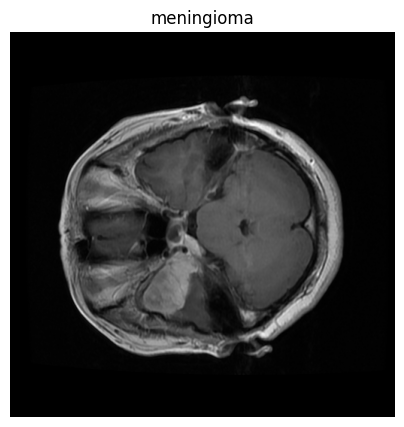

In [10]:
sample = df[df["source"]=="cheng"].iloc[0]


img = Image.open(
    IMAGE_DIR / sample["image"]
)


plt.figure(figsize=(5,5))
plt.imshow(img,cmap="gray")
plt.title(sample["class"])
plt.axis("off")
plt.show()

Correcting Image Orientation

In [11]:
cheng_rows = df[
    df["source"]=="cheng"
]

In [15]:
for idx,row in tqdm(cheng_rows.iterrows()):

    img_path = IMAGE_DIR / row["image"]

    mask_path = MASK_DIR / row["mask"]


    img = np.array(
        Image.open(img_path)
    )


    mask = np.array(
        Image.open(mask_path)
    )


    img = img.T

    mask = mask.T


    Image.fromarray(
        img
    ).save(img_path)


    Image.fromarray(
        mask
    ).save(mask_path)

3064it [38:25,  1.33it/s]


Save correct metadata

In [21]:
df.to_csv(
    METADATA_PATH,
    index=False
)

print("Metadata updated")

Metadata updated


Verify Mask Allignment

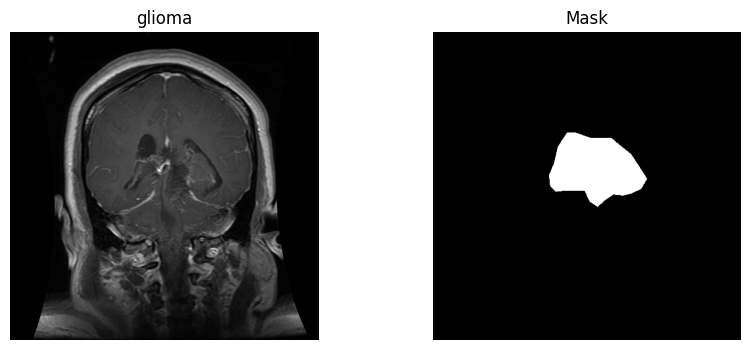

In [22]:
row = df[
    df["source"]=="cheng"
].sample(1).iloc[0]


img = Image.open(
    IMAGE_DIR / row["image"]
)

mask = Image.open(
    MASK_DIR / row["mask"]
)


plt.figure(figsize=(10,4))


plt.subplot(1,2,1)
plt.imshow(img,cmap="gray")
plt.title(row["class"])
plt.axis("off")


plt.subplot(1,2,2)
plt.imshow(mask,cmap="gray")
plt.title("Mask")
plt.axis("off")


plt.show()